
Mean pairwise branch disagreement:
                RGB  Fingerprint    JPEG  Frequency
RGB             NaN       0.1172  0.3007     0.2667
Fingerprint  0.1172          NaN  0.3188     0.2969
JPEG         0.3007       0.3188     NaN     0.2373
Frequency    0.2667       0.2969  0.2373        NaN


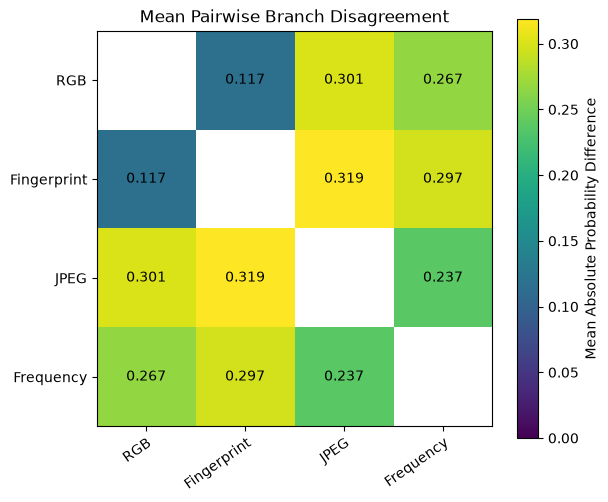


Saved PNG to: E3_adaptive_film/figures/branch_disagreement_matrix.png
Saved PDF to: E3_adaptive_film/figures/branch_disagreement_matrix.pdf


In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Paths
# ---------------------------------------------------------
INPUT_CSV = Path("outputs_agrfn_wilddeepfake_ablation/E3_adaptive_film/disagreement_matrices.csv")
OUTPUT_DIR = Path("E3_adaptive_film/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PNG = OUTPUT_DIR / "branch_disagreement_matrix.png"
OUTPUT_PDF = OUTPUT_DIR / "branch_disagreement_matrix.pdf"


# ---------------------------------------------------------
# Load disagreement results
# ---------------------------------------------------------
df = pd.read_csv(INPUT_CSV)

branches = ["RGB", "Fingerprint", "JPEG", "Frequency"]

pair_columns = {
    ("RGB", "Fingerprint"): "disagree_rgb__fingerprint",
    ("RGB", "JPEG"): "disagree_rgb__jpeg",
    ("RGB", "Frequency"): "disagree_rgb__freq",
    ("Fingerprint", "JPEG"): "disagree_fingerprint__jpeg",
    ("Fingerprint", "Frequency"): "disagree_fingerprint__freq",
    ("JPEG", "Frequency"): "disagree_jpeg__freq",
}


# ---------------------------------------------------------
# Construct symmetric mean disagreement matrix
# ---------------------------------------------------------
matrix = pd.DataFrame(
    np.nan,
    index=branches,
    columns=branches,
    dtype=float,
)

for (branch_a, branch_b), column in pair_columns.items():
    mean_disagreement = df[column].mean()

    matrix.loc[branch_a, branch_b] = mean_disagreement
    matrix.loc[branch_b, branch_a] = mean_disagreement


print("\nMean pairwise branch disagreement:")
print(matrix.round(4))


# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.2, 5.2))

masked_matrix = np.ma.masked_invalid(matrix.values)

image = ax.imshow(
    masked_matrix,
    vmin=0,
    vmax=np.nanmax(matrix.values),
    aspect="equal"
)

ax.set_xticks(np.arange(len(branches)))
ax.set_yticks(np.arange(len(branches)))

ax.set_xticklabels(branches)
ax.set_yticklabels(branches)

plt.setp(
    ax.get_xticklabels(),
    rotation=35,
    ha="right",
    rotation_mode="anchor"
)

# Add numeric values
for i in range(len(branches)):
    for j in range(len(branches)):
        value = matrix.iloc[i, j]

        if not np.isnan(value):
            ax.text(
                j,
                i,
                f"{value:.3f}",
                ha="center",
                va="center"
            )

ax.set_title("Mean Pairwise Branch Disagreement")

cbar = fig.colorbar(image, ax=ax)
cbar.set_label("Mean Absolute Probability Difference")

fig.tight_layout()

fig.savefig(
    OUTPUT_PNG,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_PDF,
    bbox_inches="tight"
)

plt.show()

print(f"\nSaved PNG to: {OUTPUT_PNG}")
print(f"Saved PDF to: {OUTPUT_PDF}")

In [8]:
!pip install numpy pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 522.9 kB/s eta 0:00:00a 0:00:01
  Using cached contourpy-1.3.3-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.0/125.0 kB 233.3 kB/s eta 0:00:0000:01
  Using cached kiwisolver-1.5.1-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 44.7 MB/s eta 0:00:00:00:01
Using cached contourpy-1.3.3-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (355 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 16.9 MB/s eta 0:00:00:00:01
Using cached kiwisolver-1.5.1-cp311-cp311-manylinux2

In [12]:
# ============================================================
# Monitor GenD + FreqDebias reverse eval
# ============================================================

from pathlib import Path
import subprocess
import time

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
REVERSE_ROOT = PROJECT_ROOT / "outputs_reverse_cross_dataset_df40_to_wilddeepfake"
LOG_DIR = REVERSE_ROOT / "logs"

PID_PATH = REVERSE_ROOT / "gend_freqdebias_reverse_master.pid"
MASTER_LOG = REVERSE_ROOT / "gend_freqdebias_reverse_master.log"

print("=" * 100)
print("GenD + FreqDebias reverse eval status")
print("=" * 100)

if PID_PATH.exists():
    pid = PID_PATH.read_text().strip()
    print("PID:", pid)
    print(subprocess.run(
        ["bash", "-lc", f"ps -p {pid} -o pid,ppid,etime,stat,%cpu,%mem,cmd || true"],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    ).stdout)
else:
    print("No PID file.")

print("\nGPU:")
print(subprocess.run(
    ["bash", "-lc", "nvidia-smi --query-compute-apps=pid,process_name,used_memory --format=csv,noheader,nounits || true"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
).stdout)

print("\nOutput files:")
for p in sorted(REVERSE_ROOT.rglob("*")):
    if p.is_file():
        age_min = (time.time() - p.stat().st_mtime) / 60
        size_mb = p.stat().st_size / 1024**2
        print(f"{str(p.relative_to(REVERSE_ROOT)):90s} size_mb={size_mb:8.3f} age_min={age_min:7.1f}")

print("\nMaster log tail:")
if MASTER_LOG.exists():
    print(subprocess.run(
        ["bash", "-lc", f"tail -n 80 {str(MASTER_LOG)!r}"],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    ).stdout)

for log_name in [
    "gend_df40_to_wilddeepfake.log",
    "freqdebias_df40_to_wilddeepfake.log",
]:
    log_path = LOG_DIR / log_name
    print("\n" + "-" * 100)
    print(log_name)
    print("-" * 100)

    if log_path.exists():
        print(subprocess.run(
            ["bash", "-lc", f"tail -n 120 {str(log_path)!r}"],
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
        ).stdout)
    else:
        print("No log yet.")

GenD + FreqDebias reverse eval status
PID: 633
    PID    PPID     ELAPSED STAT %CPU %MEM CMD


GPU:
142, /opt/conda/bin/python, 630


Output files:
agrfn_df40_to_wilddeepfake/label_audit_samples.csv                                         size_mb=   0.005 age_min=   15.7
checkpoint_inventory_df40_trained.csv                                                      size_mb=   0.002 age_min=   49.8
freqdebias_df40_to_wilddeepfake/experiment_summary.csv                                     size_mb=   0.000 age_min=    0.4
freqdebias_df40_to_wilddeepfake/test_frame_predictions.csv                                 size_mb=   4.656 age_min=    0.4
freqdebias_df40_to_wilddeepfake/test_inference_time.csv                                    size_mb=   0.000 age_min=    0.4
freqdebias_df40_to_wilddeepfake/test_metrics.csv                                           size_mb=   0.000 age_min=    0.4
freqdebias_df40_to_wilddeepfake/test_video_predictions.csv                                 size_mb=   0.065

In [8]:
# ============================================================
# AdaGate full WildDeepfake test evaluation
# Computes: Accuracy, AUPRC, AUCROC, EER,
# Precision/Recall/F1 for class 0 and class 1, Uncertain Rate
# ============================================================

from pathlib import Path
import sys
import os
import json
import time
import inspect
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    precision_recall_fscore_support,
)

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
ADAGATE_ROOT = PROJECT_ROOT / "AdaGate-DF"
SRC = ADAGATE_ROOT / "src"

TRAIN_OUT_DIR = PROJECT_ROOT / "outputs_adagate_wilddeepfake_train"
CKPT_PATH = TRAIN_OUT_DIR / "best_gated_dual_branch_wilddeepfake.pt"

# This is the repo-compatible manifest we created for training.
WILD_REPO_MANIFEST = TRAIN_OUT_DIR / "manifests/wilddeepfake_adagate_32fpv_repo_compat.csv"

FULL_METRICS_JSON = TRAIN_OUT_DIR / "wilddeepfake_test_metrics_full.json"
FULL_METRICS_CSV = TRAIN_OUT_DIR / "wilddeepfake_test_metrics_full.csv"
TABLE_ROW_CSV = TRAIN_OUT_DIR / "wilddeepfake_test_table_row_adagate.csv"

for p in [SRC, ADAGATE_ROOT]:
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.insert(0, p_str)
    os.environ["PYTHONPATH"] = p_str + ":" + os.environ.get("PYTHONPATH", "")

from deepfake_lowres.data.manifests import load_ffpp_metadata
from deepfake_lowres.data.gated_dataset import GatedMultiResolutionDataset
from deepfake_lowres.models.gated_dual_branch import GatedDualBranchDeepfakeNet
import deepfake_lowres.training.gated_runner as gated_runner
from deepfake_lowres.utils import get_device

print("=" * 100)
print("1. Load checkpoint")
print("=" * 100)

if not CKPT_PATH.exists():
    raise FileNotFoundError(CKPT_PATH)

if not WILD_REPO_MANIFEST.exists():
    raise FileNotFoundError(WILD_REPO_MANIFEST)

device = get_device()
print("Device:", device)
print("Checkpoint:", CKPT_PATH)

ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
ckpt_config = ckpt.get("config", {})

print("Checkpoint keys:", list(ckpt.keys()))
print("Best val AUC:", ckpt.get("best_val_auc", "not found"))
print("Checkpoint config:")
print(json.dumps(ckpt_config, indent=2, default=str))

print("\n" + "=" * 100)
print("2. Load WildDeepfake test split")
print("=" * 100)

df = load_ffpp_metadata(str(WILD_REPO_MANIFEST))
df = df.loc[:, ~df.columns.duplicated()].copy()

test_df = df[df["split"].astype(str).str.lower() == "test"].reset_index(drop=True)

print("Total rows:", len(df))
print("Test rows:", len(test_df))
print("Test videos:", test_df["video_id"].nunique() if "video_id" in test_df.columns else "unknown")
display(pd.crosstab(test_df["split"], test_df["label"]))

if len(test_df) == 0:
    raise RuntimeError("No WildDeepfake test rows found.")

print("\n" + "=" * 100)
print("3. Build AdaGate model")
print("=" * 100)

resolutions = ckpt_config.get("resolutions", [128, 224, 256, 384])
image_size = int(ckpt_config.get("image_size_for_model", ckpt_config.get("image_size", 224)))
branch_channels = ckpt_config.get("branch_channels", [12, 20, 32, 48])
threshold = float(ckpt_config.get("uncertain_threshold", 0.65))

print("resolutions:", resolutions)
print("image_size:", image_size)
print("branch_channels:", branch_channels)
print("uncertain threshold:", threshold)

sig = inspect.signature(GatedDualBranchDeepfakeNet)
print("Model signature:", sig)

def make_model():
    params = sig.parameters
    kwargs = {}

    candidate_values = {
        "resolutions": resolutions,
        "image_size": image_size,
        "image_size_for_model": image_size,
        "branch_channels": branch_channels,
        "num_classes": 2,
        "n_classes": 2,
    }

    for name in params:
        if name != "self" and name in candidate_values:
            kwargs[name] = candidate_values[name]

    try:
        print("Trying model kwargs:", kwargs)
        return GatedDualBranchDeepfakeNet(**kwargs)
    except TypeError as e:
        print("Constructor failed:", repr(e))

    for fallback_kwargs in [
        {"resolutions": resolutions, "branch_channels": branch_channels},
        {"resolutions": resolutions},
        {"branch_channels": branch_channels},
        {},
    ]:
        try:
            print("Trying fallback:", fallback_kwargs)
            return GatedDualBranchDeepfakeNet(**fallback_kwargs)
        except TypeError as e:
            print("Fallback failed:", repr(e))

    raise RuntimeError("Could not instantiate GatedDualBranchDeepfakeNet.")

model = make_model().to(device)

state = ckpt.get("model", ckpt.get("state_dict", ckpt))
missing_keys, unexpected_keys = model.load_state_dict(state, strict=False)

print("Missing keys:", missing_keys)
print("Unexpected keys:", unexpected_keys)

model.eval()

print("\n" + "=" * 100)
print("4. Build test DataLoader")
print("=" * 100)

batch_size = 32
num_workers = 2

dataset = GatedMultiResolutionDataset(
    test_df,
    image_size=image_size,
    resolutions=resolutions,
    mode="test",
    cache_features=False,
)

loader_kwargs = dict(
    dataset=dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    drop_last=False,
)

if num_workers > 0:
    loader_kwargs["pin_memory"] = True
    loader_kwargs["persistent_workers"] = True
    loader_kwargs["prefetch_factor"] = 2

test_loader = DataLoader(**loader_kwargs)

print("Dataset rows:", len(dataset))
print("Batch size:", batch_size)
print("Num workers:", num_workers)
print("Batches:", len(test_loader))

print("\n" + "=" * 100)
print("5. Patch metric function to include AUPRC and EER")
print("=" * 100)

original_metric_fn = gated_runner.compute_multiclass_binary_metrics

def compute_eer(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)

    fpr, tpr, _ = roc_curve(y_true, y_score)
    fnr = 1.0 - tpr

    idx = np.nanargmin(np.abs(fpr - fnr))
    eer = float((fpr[idx] + fnr[idx]) / 2.0)
    return eer

def positive_scores_from_any(score_like):
    arr = np.asarray(score_like)

    if arr.ndim == 2:
        if arr.shape[1] >= 2:
            return arr[:, 1]
        return arr[:, 0]

    return arr.reshape(-1)

def patched_metric_fn(*args, **kwargs):
    base = original_metric_fn(*args, **kwargs)

    # The repo normally calls this with y_true and score/probabilities
    # as the first two positional arguments.
    if len(args) >= 2:
        y_true = np.asarray(args[0]).astype(int)
        y_score = positive_scores_from_any(args[1])
    else:
        y_true = np.asarray(
            kwargs.get("y_true", kwargs.get("labels", kwargs.get("targets")))
        ).astype(int)

        score_arg = kwargs.get(
            "y_score",
            kwargs.get("scores", kwargs.get("probs", kwargs.get("probabilities")))
        )
        y_score = positive_scores_from_any(score_arg)

    # Derive hard predictions from the original confusion matrix if available.
    if "confusion_matrix" in base:
        cm = np.asarray(base["confusion_matrix"])
    else:
        y_pred = (y_score >= 0.5).astype(int)
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    # To compute class metrics, recover y_pred from scores using 0.5.
    # This matches standard binary reporting. The repo's uncertainty value
    # remains exactly from its own evaluation.
    y_pred = (y_score >= 0.5).astype(int)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1],
        zero_division=0,
    )

    try:
        auprc = float(average_precision_score(y_true, y_score))
    except Exception:
        auprc = float("nan")

    try:
        aucroc = float(roc_auc_score(y_true, y_score))
    except Exception:
        aucroc = float(base.get("auc", float("nan")))

    try:
        eer = compute_eer(y_true, y_score)
    except Exception:
        eer = float("nan")

    base["auprc"] = auprc
    base["auc"] = aucroc
    base["aucroc"] = aucroc
    base["eer"] = eer

    base["precision_0"] = float(precision[0])
    base["recall_0"] = float(recall[0])
    base["f1_0"] = float(f1[0])
    base["precision_1"] = float(precision[1])
    base["recall_1"] = float(recall[1])
    base["f1_1"] = float(f1[1])

    base["support_0"] = int(support[0])
    base["support_1"] = int(support[1])

    return base

gated_runner.compute_multiclass_binary_metrics = patched_metric_fn

print("Metric function patched for this notebook process.")

print("\n" + "=" * 100)
print("6. Evaluate WildDeepfake test split")
print("=" * 100)

t0 = time.time()

metrics = gated_runner.evaluate_gated_model(
    model,
    test_loader,
    device,
    threshold=threshold,
)

elapsed = time.time() - t0

metrics = dict(metrics)
metrics["dataset"] = "WildDeepfake"
metrics["split"] = "test"
metrics["checkpoint"] = str(CKPT_PATH)
metrics["manifest"] = str(WILD_REPO_MANIFEST)
metrics["num_frames"] = int(len(test_df))
metrics["num_videos"] = int(test_df["video_id"].nunique()) if "video_id" in test_df.columns else None
metrics["threshold"] = threshold
metrics["elapsed_sec"] = float(elapsed)
metrics["frames_per_second"] = float(len(test_df) / max(elapsed, 1e-9))
metrics["seconds_per_frame"] = float(elapsed / max(len(test_df), 1))

with open(FULL_METRICS_JSON, "w") as f:
    json.dump(metrics, f, indent=2, default=str)

pd.DataFrame([metrics]).to_csv(FULL_METRICS_CSV, index=False)

print("Saved full metrics JSON:", FULL_METRICS_JSON)
print("Saved full metrics CSV:", FULL_METRICS_CSV)

print("\nRaw full metrics:")
print(json.dumps(metrics, indent=2, default=str))

print("\n" + "=" * 100)
print("7. Create paper table row")
print("=" * 100)

row = {
    "Model": "AdaGate",
    "Accuracy": 100.0 * metrics.get("accuracy", np.nan),
    "AUPRC": 100.0 * metrics.get("auprc", np.nan),
    "AUCROC": 100.0 * metrics.get("aucroc", metrics.get("auc", np.nan)),
    "EER (Equal Error Rate)": 100.0 * metrics.get("eer", np.nan),
    "Precision (0)": 100.0 * metrics.get("precision_0", np.nan),
    "Recall (0)": 100.0 * metrics.get("recall_0", np.nan),
    "F1 (0)": 100.0 * metrics.get("f1_0", np.nan),
    "Precision (1)": 100.0 * metrics.get("precision_1", metrics.get("precision", np.nan)),
    "Recall (1)": 100.0 * metrics.get("recall_1", metrics.get("recall", np.nan)),
    "F1 (1)": 100.0 * metrics.get("f1_1", metrics.get("f1", np.nan)),
    "Uncertain Rate (%)": metrics.get("uncertain_rate_pct", np.nan),
}

table_row = pd.DataFrame([row])

# Round for paper display.
for col in table_row.columns:
    if col != "Model":
        table_row[col] = table_row[col].astype(float).round(2)

table_row.to_csv(TABLE_ROW_CSV, index=False)

print("Saved table row:", TABLE_ROW_CSV)
display(table_row)

print("\nPasteable TSV row:")
print(table_row.to_csv(sep="\t", index=False).strip())

1. Load checkpoint
Device: cuda
Checkpoint: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/best_gated_dual_branch_wilddeepfake.pt
Checkpoint keys: ['model', 'config', 'best_val_auc']
Best val AUC: 0.8248383812619726
Checkpoint config:
{
  "dataset": "wilddeepfake",
  "metadata_csv": "/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/manifests/wilddeepfake_adagate_32fpv_repo_compat.csv",
  "balance_mode": "none",
  "model": "gated_dual_branch",
  "out_dir": "/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train",
  "ckpt_name": "best_gated_dual_branch_wilddeepfake.pt",
  "resolutions": [
    128,
    224,
    256,
    384
  ],
  "image_size_for_model": 224,
  "batch_size": 32,
  "num_workers": 2,
  "epochs": 10,
  "lr": 0.0002,
  "weight_decay": 0.0001,
  "mixed_precision": true,
  "uncertain_threshold": 0.65,
  "branch_channels": [
    12,
    20,
    32,
    48
  ],
  "cache_feature

label,0,1
split,,
test,12672,13120



3. Build AdaGate model
resolutions: [128, 224, 256, 384]
image_size: 224
branch_channels: [12, 20, 32, 48]
uncertain threshold: 0.65
Model signature: (branch_channels=(12, 20, 32, 48), gate_features=6, num_classes=2)
Trying model kwargs: {'branch_channels': [12, 20, 32, 48], 'num_classes': 2}
Missing keys: []
Unexpected keys: []

4. Build test DataLoader
Dataset rows: 25792
Batch size: 32
Num workers: 2
Batches: 806

5. Patch metric function to include AUPRC and EER
Metric function patched for this notebook process.

6. Evaluate WildDeepfake test split


Saved full metrics JSON: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/wilddeepfake_test_metrics_full.json
Saved full metrics CSV: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/wilddeepfake_test_metrics_full.csv

Raw full metrics:
{
  "accuracy": 0.6631125930521092,
  "auc": 0.6649678954175905,
  "precision": 0.7168869309838473,
  "recall": 0.558155487804878,
  "f1": 0.6276408827940861,
  "confusion_matrix": [
    [
      9780,
      2892
    ],
    [
      5797,
      7323
    ]
  ],
  "auprc": 0.6248939900488466,
  "aucroc": 0.6649678954175905,
  "eer": 0.3350321045824095,
  "precision_0": 0.6278487513641908,
  "recall_0": 0.771780303030303,
  "f1_0": 0.692413890757195,
  "precision_1": 0.7168869309838473,
  "recall_1": 0.558155487804878,
  "f1_1": 0.6276408827940861,
  "support_0": 12672,
  "support_1": 13120,
  "num_samples": 25792,
  "uncertain_rate_pct": 26.546991315136477,
  "route_usage": {
    "fast_

,Model,Accuracy,AUPRC,AUCROC,EER (Equal Error Rate),Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),Uncertain Rate (%)
0,AdaGate,66.31,62.49,66.5,33.5,62.78,77.18,69.24,71.69,55.82,62.76,26.55



Pasteable TSV row:
Model	Accuracy	AUPRC	AUCROC	EER (Equal Error Rate)	Precision (0)	Recall (0)	F1 (0)	Precision (1)	Recall (1)	F1 (1)	Uncertain Rate (%)
AdaGate	66.31	62.49	66.5	33.5	62.78	77.18	69.24	71.69	55.82	62.76	26.55


In [4]:
!pip install numpy transformers pandas torchvision scikit-learn opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl (73.8 MB)


In [14]:
# ============================================================
# GenD WildDeepfake -> corrected DF40 fake_test evaluation
# ============================================================

from pathlib import Path
import pandas as pd
import subprocess
import sys
import shlex

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")

SCRIPT = PROJECT_ROOT / "gend_reimpl_ffpp.py"
TRAIN_OUT = PROJECT_ROOT / "outputs_gend_wilddeepfake_train"

BASE_MANIFEST = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_gend_safe.csv"

OUT_DIR = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/gend_wilddeepfake_to_df40_fake_test"
OUT_DIR.mkdir(parents=True, exist_ok=True)

EVAL_COMPAT_MANIFEST = OUT_DIR / "df40_fake_test_manifest_gend_eval_compat.csv"
LOG_PATH = OUT_DIR / "gend_wilddeepfake_to_df40_fake_test.log"
PID_PATH = OUT_DIR / "gend_wilddeepfake_to_df40_fake_test.pid"

checkpoint_candidates = [
    TRAIN_OUT / "best_checkpoint.pt",
    TRAIN_OUT / "gend_best.pt",
    TRAIN_OUT / "latest_checkpoint.pt",
    TRAIN_OUT / "gend_latest.pt",
    TRAIN_OUT / "best_model.pt",
    TRAIN_OUT / "latest_model.pt",
]

CKPT = None
for p in checkpoint_candidates:
    if p.exists():
        CKPT = p
        break

if CKPT is None:
    print("Files in GenD training output:")
    for p in sorted(TRAIN_OUT.glob("*")):
        print(p.name)
    raise FileNotFoundError("Could not find GenD checkpoint.")

print("Using checkpoint:", CKPT)

df_test = pd.read_csv(BASE_MANIFEST)

df_test["split"] = "test"
df_test["label"] = df_test["label"].astype(int)
df_test["video_id"] = df_test["video_id"].astype(str)

if "image_path" in df_test.columns:
    df_test = df_test.drop(columns=["image_path"])

# Dummy train/val only to stop script from crashing before eval_only
dummy_videos = df_test["video_id"].drop_duplicates().head(2).tolist()
dummy_small = (
    df_test[df_test["video_id"].isin(dummy_videos)]
    .sort_values(["video_id", "frame_path"])
    .groupby("video_id", group_keys=False)
    .head(32)
    .copy()
)

df_train_dummy = dummy_small.copy()
df_train_dummy["split"] = "train"
df_train_dummy["eval_only_dummy_split"] = True

df_val_dummy = dummy_small.copy()
df_val_dummy["split"] = "val"
df_val_dummy["eval_only_dummy_split"] = True

df_test["eval_only_dummy_split"] = False

df_eval = pd.concat([df_train_dummy, df_val_dummy, df_test], ignore_index=True)

if "image_path" in df_eval.columns:
    df_eval = df_eval.drop(columns=["image_path"])

df_eval.to_csv(EVAL_COMPAT_MANIFEST, index=False)

print("\nEval-compatible manifest:")
print(EVAL_COMPAT_MANIFEST)

print("\nSplit/label counts:")
display(pd.crosstab(df_eval["split"], df_eval["label"]))

print("\nUnique videos:")
display(df_eval.groupby("split")["video_id"].nunique())

cmd = [
    sys.executable, "-u", str(SCRIPT),
    "--metadata_csv", str(EVAL_COMPAT_MANIFEST),
    "--out_dir", str(OUT_DIR),
    "--checkpoint", str(CKPT),
    "--eval_only",
    "--split", "test",
    "--batch_size", "16",
    "--frames_per_video", "32",
    "--image_size", "224",
    "--num_workers", "4",
    "--amp",
]

print("\nCommand:")
print(" ".join(shlex.quote(x) for x in cmd))

bash_cmd = (
    "cd " + shlex.quote(str(PROJECT_ROOT)) + " && "
    "PYTHONUNBUFFERED=1 nohup " + " ".join(shlex.quote(x) for x in cmd) +
    " > " + shlex.quote(str(LOG_PATH)) + " 2>&1 & echo $!"
)

proc = subprocess.run(
    ["bash", "-lc", bash_cmd],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

pid = proc.stdout.strip().splitlines()[-1]
PID_PATH.write_text(pid)

print("\nLaunched GenD corrected fake_test eval PID:", pid)
print("Log:", LOG_PATH)

Using checkpoint: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_gend_wilddeepfake_train/best_checkpoint.pt

Eval-compatible manifest:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/gend_wilddeepfake_to_df40_fake_test/df40_fake_test_manifest_gend_eval_compat.csv

Split/label counts:


label,1
split,
test,175667
train,2
val,2



Unique videos:


split
test     5513
train       2
val         2
Name: video_id, dtype: int64


Command:
/opt/conda/bin/python -u '/home/jovyan/Deepfake_Low Resource_Low Resolution/gend_reimpl_ffpp.py' --metadata_csv '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/gend_wilddeepfake_to_df40_fake_test/df40_fake_test_manifest_gend_eval_compat.csv' --out_dir '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/gend_wilddeepfake_to_df40_fake_test' --checkpoint '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_gend_wilddeepfake_train/best_checkpoint.pt' --eval_only --split test --batch_size 16 --frames_per_video 32 --image_size 224 --num_workers 4 --amp

Launched GenD corrected fake_test eval PID: 576
Log: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/gend_wilddeepfake_to_df40_fake_test/gend_wilddeepfake_to_df40_fake_test.log


In [13]:
# ============================================================
# Rebuild DF40 fake_test manifest with corrected video_id
# video_id = relative parent folder under fake_test
# ============================================================

from pathlib import Path
import pandas as pd
import time

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")

RUN_ROOT = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test"
MANIFEST_DIR = RUN_ROOT / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

OLD_MASTER = MANIFEST_DIR / "df40_fake_test_manifest_master.csv"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

# Try to recover source_root from previous manifest
FAKE_TEST_DIR = None

if OLD_MASTER.exists():
    old_df = pd.read_csv(OLD_MASTER, nrows=5)
    if "source_root" in old_df.columns:
        candidate = Path(str(old_df["source_root"].iloc[0]))
        if candidate.exists():
            FAKE_TEST_DIR = candidate

# Fallback search
if FAKE_TEST_DIR is None:
    known_candidates = [
        PROJECT_ROOT / "DF40/fake_test",
        PROJECT_ROOT / "df40/fake_test",
        PROJECT_ROOT / "DF40/test/fake_test",
        PROJECT_ROOT / "df40/test/fake_test",
        PROJECT_ROOT / "DF40/test/fake",
        PROJECT_ROOT / "df40/test/fake",
    ]

    for p in known_candidates:
        if p.exists() and p.is_dir():
            FAKE_TEST_DIR = p
            break

if FAKE_TEST_DIR is None:
    hits = []
    for p in PROJECT_ROOT.rglob("*"):
        if p.is_dir() and p.name.lower() == "fake_test":
            hits.append(p)

    if not hits:
        raise FileNotFoundError("Could not find fake_test folder.")

    print("Found fake_test candidates:")
    for i, p in enumerate(hits):
        print(f"[{i}] {p}")

    FAKE_TEST_DIR = hits[0]

print("Using FAKE_TEST_DIR:")
print(FAKE_TEST_DIR)

# Crawl images
start = time.time()
image_paths = sorted(
    p for p in FAKE_TEST_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
print("\nImages found:", len(image_paths))
print("Crawl time:", round(time.time() - start, 2), "seconds")

if len(image_paths) == 0:
    raise RuntimeError(f"No images found under {FAKE_TEST_DIR}")

def corrected_video_id(path: Path, root: Path) -> str:
    rel = path.relative_to(root)

    # Use the relative parent folder as the group/video id.
    # Example:
    # fake_test/method_x/video_123/frame_001.png -> method_x/video_123
    parent = rel.parent

    if str(parent) == ".":
        return path.stem

    return str(parent)

def method_name(path: Path, root: Path) -> str:
    rel = path.relative_to(root)
    if len(rel.parts) >= 2:
        return rel.parts[0]
    return "fake_test"

rows = []

for p in image_paths:
    rel = p.relative_to(FAKE_TEST_DIR)
    vid = corrected_video_id(p, FAKE_TEST_DIR)
    method = method_name(p, FAKE_TEST_DIR)

    rows.append({
        "frame_path": str(p),
        "image_path": str(p),
        "label": 1,
        "label_name": "fake",
        "split": "test",
        "dataset": "DF40",
        "domain": "DF40",
        "dataset_partition": "fake_test",
        "top_level_folder": "fake_test",
        "method": method,
        "video_id": vid,
        "group_id": vid,
        "sample_unit_id": vid,
        "relative_path": str(rel),
        "source_root": str(FAKE_TEST_DIR),
    })

df = pd.DataFrame(rows)
df = df.sort_values(["video_id", "relative_path"]).reset_index(drop=True)

MASTER_MANIFEST = MANIFEST_DIR / "df40_fake_test_manifest_master.csv"
GEND_SAFE_MANIFEST = MANIFEST_DIR / "df40_fake_test_manifest_gend_safe.csv"
FREQDEBIAS_SAFE_MANIFEST = MANIFEST_DIR / "df40_fake_test_manifest_freqdebias_safe.csv"
AGRFN_SAFE_MANIFEST = MANIFEST_DIR / "df40_fake_test_manifest_agrfn_safe.csv"
DFDHR_SAFE_MANIFEST = MANIFEST_DIR / "df40_fake_test_manifest_dfdhr_safe.csv"
SUMMARY_CSV = MANIFEST_DIR / "manifest_summary.csv"

df.to_csv(MASTER_MANIFEST, index=False)

safe_no_image_path = df.drop(columns=["image_path"])
safe_no_image_path.to_csv(GEND_SAFE_MANIFEST, index=False)
safe_no_image_path.to_csv(FREQDEBIAS_SAFE_MANIFEST, index=False)

df.to_csv(AGRFN_SAFE_MANIFEST, index=False)
df.to_csv(DFDHR_SAFE_MANIFEST, index=False)

summary_df = pd.DataFrame([
    {
        "manifest": "master",
        "path": str(MASTER_MANIFEST),
        "rows": len(df),
        "unique_videos": df["video_id"].nunique(),
        "label_1_fake_rows": int((df["label"] == 1).sum()),
    },
    {
        "manifest": "gend_safe",
        "path": str(GEND_SAFE_MANIFEST),
        "rows": len(safe_no_image_path),
        "unique_videos": safe_no_image_path["video_id"].nunique(),
        "label_1_fake_rows": int((safe_no_image_path["label"] == 1).sum()),
    },
    {
        "manifest": "freqdebias_safe",
        "path": str(FREQDEBIAS_SAFE_MANIFEST),
        "rows": len(safe_no_image_path),
        "unique_videos": safe_no_image_path["video_id"].nunique(),
        "label_1_fake_rows": int((safe_no_image_path["label"] == 1).sum()),
    },
    {
        "manifest": "agrfn_safe",
        "path": str(AGRFN_SAFE_MANIFEST),
        "rows": len(df),
        "unique_videos": df["video_id"].nunique(),
        "label_1_fake_rows": int((df["label"] == 1).sum()),
    },
    {
        "manifest": "dfdhr_safe",
        "path": str(DFDHR_SAFE_MANIFEST),
        "rows": len(df),
        "unique_videos": df["video_id"].nunique(),
        "label_1_fake_rows": int((df["label"] == 1).sum()),
    },
])
summary_df.to_csv(SUMMARY_CSV, index=False)

print("\nSaved corrected manifests:")
for p in [MASTER_MANIFEST, GEND_SAFE_MANIFEST, FREQDEBIAS_SAFE_MANIFEST, AGRFN_SAFE_MANIFEST, DFDHR_SAFE_MANIFEST, SUMMARY_CSV]:
    print(p)

print("\nSummary:")
display(summary_df)

print("\nRows:", len(df))
print("Unique video_id:", df["video_id"].nunique())
print("Methods/top folders:")
display(df["method"].value_counts().head(20))

print("\nFrames per video summary:")
display(df.groupby("video_id").size().describe())

print("\nPreview:")
display(df.head())

Using FAKE_TEST_DIR:
/home/jovyan/Deepfake_Low Resource_Low Resolution/df40/Fake_Test

Images found: 175667
Crawl time: 3.62 seconds

Saved corrected manifests:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_master.csv
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_gend_safe.csv
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_freqdebias_safe.csv
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_agrfn_safe.csv
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_dfdhr_safe.csv
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/manifest_summary.csv

Summary:


,manifest,path,rows,unique_videos,label_1_fake_rows
0,master,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,5513,175667
1,gend_safe,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,5513,175667
2,freqdebias_safe,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,5513,175667
3,agrfn_safe,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,5513,175667
4,dfdhr_safe,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,5513,175667



Rows: 175667
Unique video_id: 5513
Methods/top folders:


method
cdf            46190
DiT            31885
ddim           31885
blendface      24790
danet          23696
ff             10552
deepfacelab     4669
CollabDiff      2000
Name: count, dtype: int64


Frames per video summary:


count    5513.000000
mean       31.864139
std        24.479232
min         1.000000
25%        31.000000
50%        32.000000
75%        32.000000
max      1000.000000
dtype: float64


Preview:


,frame_path,image_path,label,label_name,split,dataset,domain,dataset_partition,top_level_folder,method,video_id,group_id,sample_unit_id,relative_path,source_root
0,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1,fake,test,DF40,DF40,fake_test,fake_test,CollabDiff,CollabDiff/fake/0,CollabDiff/fake/0,CollabDiff/fake/0,CollabDiff/fake/0/000000_x_0.png,/home/jovyan/Deepfake_Low Resource_Low Resolut...
1,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1,fake,test,DF40,DF40,fake_test,fake_test,CollabDiff,CollabDiff/fake/1,CollabDiff/fake/1,CollabDiff/fake/1,CollabDiff/fake/1/000000_x_0.png,/home/jovyan/Deepfake_Low Resource_Low Resolut...
2,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1,fake,test,DF40,DF40,fake_test,fake_test,CollabDiff,CollabDiff/fake/10,CollabDiff/fake/10,CollabDiff/fake/10,CollabDiff/fake/10/000000_x_0.png,/home/jovyan/Deepfake_Low Resource_Low Resolut...
3,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1,fake,test,DF40,DF40,fake_test,fake_test,CollabDiff,CollabDiff/fake/100,CollabDiff/fake/100,CollabDiff/fake/100,CollabDiff/fake/100/000000_x_0.png,/home/jovyan/Deepfake_Low Resource_Low Resolut...
4,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1,fake,test,DF40,DF40,fake_test,fake_test,CollabDiff,CollabDiff/fake/101,CollabDiff/fake/101,CollabDiff/fake/101,CollabDiff/fake/101/000000_x_0.png,/home/jovyan/Deepfake_Low Resource_Low Resolut...


In [16]:
# ============================================================
# Fix PyTorch 2.6 checkpoint loading issue for DFD-HR
# Then relaunch WildDeepfake -> DF40 fake_test evaluation
# ============================================================

from pathlib import Path
import subprocess
import shlex

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
DFDHR_ROOT = PROJECT_ROOT / "DFD-HR"

SCRIPT = DFDHR_ROOT / "run_dfd_hr_df40.py"
BACKUP = DFDHR_ROOT / "run_dfd_hr_df40.py.before_weights_only_patch"

MANIFEST = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_dfdhr_safe.csv"
TRAIN_OUT = PROJECT_ROOT / "outputs_dfdhr_wilddeepfake_train_no_amp_cc"

OUT_DIR = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/dfdhr_wilddeepfake_to_df40_fake_test"
LOG_PATH = OUT_DIR / "dfdhr_wilddeepfake_to_df40_fake_test.log"
PID_PATH = OUT_DIR / "dfdhr_wilddeepfake_to_df40_fake_test.pid"

OUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Stop any stale DFD-HR eval process
# ------------------------------------------------------------

subprocess.run(
    ["bash", "-lc", "pkill -f 'run_dfd_hr_df40.py.*dfdhr_wilddeepfake_to_df40_fake_test' || true"],
    text=True,
)

# ------------------------------------------------------------
# 2. Patch torch.load in the runner
# ------------------------------------------------------------

if not SCRIPT.exists():
    raise FileNotFoundError(SCRIPT)

text = SCRIPT.read_text()

if "weights_only=False" in text:
    print("Script already patched with weights_only=False.")
else:
    if not BACKUP.exists():
        BACKUP.write_text(text)
        print("Saved backup:", BACKUP)

    old = 'torch.load(args.ckpt_path, map_location="cpu")'
    new = 'torch.load(args.ckpt_path, map_location="cpu", weights_only=False)'

    if old not in text:
        raise RuntimeError(
            "Could not find the expected torch.load line. "
            "Open run_dfd_hr_df40.py around line 284 and patch torch.load manually."
        )

    text = text.replace(old, new)
    SCRIPT.write_text(text)
    print("Patched torch.load with weights_only=False.")

# ------------------------------------------------------------
# 3. Pick checkpoint
# Prefer latest_checkpoint.pt because training stopped mid-run
# ------------------------------------------------------------

checkpoint_candidates = [
    TRAIN_OUT / "latest_checkpoint.pt",
    TRAIN_OUT / "best_checkpoint.pt",
    TRAIN_OUT / "dfdhr_latest.pt",
    TRAIN_OUT / "dfdhr_best.pt",
    TRAIN_OUT / "latest_model.pt",
    TRAIN_OUT / "best_model.pt",
]

CKPT = None
for p in checkpoint_candidates:
    if p.exists():
        CKPT = p
        break

if CKPT is None:
    print("Files in DFD-HR training output:")
    if TRAIN_OUT.exists():
        for p in sorted(TRAIN_OUT.glob("*")):
            print(" ", p.name)
    raise FileNotFoundError("Could not find DFD-HR checkpoint.")

# ------------------------------------------------------------
# 4. Locate optional YAML configs
# ------------------------------------------------------------

yaml_files = sorted(set(list(DFDHR_ROOT.rglob("*.yaml")) + list(PROJECT_ROOT.rglob("dfd_hr.yaml"))))
detector_yaml = next((p for p in yaml_files if "dfd" in p.name.lower() and "hr" in p.name.lower()), None)
test_config = next((p for p in yaml_files if "test" in p.name.lower() and "config" in p.name.lower()), None)

# ------------------------------------------------------------
# 5. Relaunch DFD-HR eval safely
# ------------------------------------------------------------

cmd = [
    "python", "-u", str(SCRIPT),
    "--repo_root", str(DFDHR_ROOT),
    "--metadata_csv", str(MANIFEST),
    "--ckpt_path", str(CKPT),
    "--out_dir", str(OUT_DIR),
    "--split", "test",
    "--image_size", "448",
    "--frames_per_video", "32",
    "--batch_size", "2",
    "--num_workers", "0",
    "--path_col", "frame_path",
    "--label_col", "label",
    "--split_col", "split",
    "--group_col", "video_id",
    "--allow_non_strict",
]

if detector_yaml is not None:
    cmd.extend(["--detector_yaml", str(detector_yaml)])

if test_config is not None:
    cmd.extend(["--test_config", str(test_config)])

print("\nUsing checkpoint:", CKPT)
print("Manifest:", MANIFEST)
print("Detector YAML:", detector_yaml)
print("Test config:", test_config)
print("Output:", OUT_DIR)
print("Log:", LOG_PATH)

print("\nCommand:")
print(" ".join(shlex.quote(x) for x in cmd))

bash_cmd = (
    "cd " + shlex.quote(str(PROJECT_ROOT)) + " && "
    "PYTHONUNBUFFERED=1 nohup " + " ".join(shlex.quote(x) for x in cmd) +
    " > " + shlex.quote(str(LOG_PATH)) + " 2>&1 & echo $!"
)

proc = subprocess.run(
    ["bash", "-lc", bash_cmd],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

pid = proc.stdout.strip().splitlines()[-1]
PID_PATH.write_text(pid)

print("\nLaunched patched DFD-HR eval PID:", pid)
print("PID saved to:", PID_PATH)
print("Log:", LOG_PATH)

Script already patched with weights_only=False.

Using checkpoint: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_dfdhr_wilddeepfake_train_no_amp_cc/latest_checkpoint.pt
Manifest: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_dfdhr_safe.csv
Detector YAML: /home/jovyan/Deepfake_Low Resource_Low Resolution/DFD-HR/training/config/detector/dfd_hr.yaml
Test config: /home/jovyan/Deepfake_Low Resource_Low Resolution/DFD-HR/training/config/test_config.yaml
Output: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/dfdhr_wilddeepfake_to_df40_fake_test
Log: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/dfdhr_wilddeepfake_to_df40_fake_test/dfdhr_wilddeepfake_to_df40_fake_test.log

Command:
python -u '/home/jovyan/Deepfake_Low Resource_Low Resolution/DFD-HR/run_dfd_hr_df40.py' --repo_root '/home/jovyan/Deepfake_Low Resource_Low Resolutio

In [18]:
# ============================================================
# DFD-HR cross-dataset fake_test evaluation
# Train: WildDeepfake
# Test: DF40 fake_test only
# ============================================================

from pathlib import Path
import subprocess
import shlex

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
DFDHR_ROOT = PROJECT_ROOT / "DFD-HR"

# DFD-HR eval runner
SCRIPT = DFDHR_ROOT / "run_dfd_hr_df40.py"

# Reusable DF40 fake_test manifest created earlier
MANIFEST = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_dfdhr_safe.csv"

# WildDeepfake-trained DFD-HR output
TRAIN_OUT = PROJECT_ROOT / "outputs_dfdhr_wilddeepfake_train_no_amp_cc"

# New output folder for this cross-dataset run
OUT_DIR = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/dfdhr_wilddeepfake_to_df40_fake_test"
LOG_PATH = OUT_DIR / "dfdhr_wilddeepfake_to_df40_fake_test.log"
PID_PATH = OUT_DIR / "dfdhr_wilddeepfake_to_df40_fake_test.pid"

OUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Find checkpoint
# ------------------------------------------------------------

checkpoint_candidates = [
    TRAIN_OUT / "best_checkpoint.pt",
    TRAIN_OUT / "latest_checkpoint.pt",
    TRAIN_OUT / "dfdhr_best.pt",
    TRAIN_OUT / "dfdhr_latest.pt",
    TRAIN_OUT / "best_model.pt",
    TRAIN_OUT / "latest_model.pt",
]

CKPT = None
for p in checkpoint_candidates:
    if p.exists():
        CKPT = p
        break

if CKPT is None:
    print("Files in DFD-HR training output:")
    if TRAIN_OUT.exists():
        for p in sorted(TRAIN_OUT.glob("*")):
            print(" ", p.name)
    raise FileNotFoundError("Could not find a DFD-HR checkpoint.")

# ------------------------------------------------------------
# 2. Find YAML configs if available
# ------------------------------------------------------------

yaml_candidates = list(DFDHR_ROOT.rglob("*.yaml")) + list(PROJECT_ROOT.rglob("dfd_hr.yaml"))
yaml_candidates = sorted(set(yaml_candidates))

detector_yaml_candidates = [
    p for p in yaml_candidates
    if "dfd" in p.name.lower() and "hr" in p.name.lower()
]

test_config_candidates = [
    p for p in yaml_candidates
    if "test" in p.name.lower() and "config" in p.name.lower()
]

DETECTOR_YAML = detector_yaml_candidates[0] if detector_yaml_candidates else None
TEST_CONFIG = test_config_candidates[0] if test_config_candidates else None

print("=" * 100)
print("Checking files")
print("=" * 100)

for p in [SCRIPT, MANIFEST, TRAIN_OUT, CKPT]:
    print("FOUND  " if p.exists() else "MISSING", p)

print("\nUsing checkpoint:")
print(CKPT)

print("\nDetector YAML:")
print(DETECTOR_YAML if DETECTOR_YAML else "NOT FOUND")

print("\nTest config YAML:")
print(TEST_CONFIG if TEST_CONFIG else "NOT FOUND")

if not SCRIPT.exists():
    raise FileNotFoundError(SCRIPT)

if not MANIFEST.exists():
    raise FileNotFoundError(MANIFEST)

if DETECTOR_YAML is None:
    print("\nNo detector YAML was found. Available YAML files:")
    for p in yaml_candidates:
        print(" ", p)
    raise FileNotFoundError(
        "Could not find dfd_hr.yaml. "
        "DFD-HR's runner needs the detector YAML unless we use a custom direct evaluator."
    )

# ------------------------------------------------------------
# 3. Build command
# ------------------------------------------------------------

cmd = [
    "python", "-u", str(SCRIPT),
    "--repo_root", str(DFDHR_ROOT),
    "--metadata_csv", str(MANIFEST),
    "--ckpt_path", str(CKPT),
    "--detector_yaml", str(DETECTOR_YAML),
    "--out_dir", str(OUT_DIR),
    "--split", "test",
    "--image_size", "448",
    "--frames_per_video", "32",
    "--batch_size", "8",
    "--num_workers", "4",
    "--path_col", "frame_path",
    "--label_col", "label",
    "--split_col", "split",
    "--group_col", "video_id",
    "--allow_non_strict",
]

if TEST_CONFIG is not None:
    cmd.extend(["--test_config", str(TEST_CONFIG)])

print("\n" + "=" * 100)
print("Launching DFD-HR WildDeepfake -> DF40 fake_test eval")
print("=" * 100)
print("Command:")
print(" ".join(shlex.quote(x) for x in cmd))
print("Output:", OUT_DIR)
print("Log:", LOG_PATH)

existing = subprocess.run(
    ["bash", "-lc", "ps aux | grep -i 'run_dfd_hr_df40.py' | grep 'dfdhr_wilddeepfake_to_df40_fake_test' | grep -v grep || true"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
).stdout.strip()

if existing:
    print("\nDFD-HR cross-test is already running. Not launching duplicate:")
    print(existing)
else:
    bash_cmd = (
        "cd " + shlex.quote(str(PROJECT_ROOT)) + " && "
        "PYTHONUNBUFFERED=1 nohup " + " ".join(shlex.quote(x) for x in cmd) +
        " > " + shlex.quote(str(LOG_PATH)) + " 2>&1 & echo $!"
    )

    proc = subprocess.run(
        ["bash", "-lc", bash_cmd],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

    pid = proc.stdout.strip().splitlines()[-1]
    PID_PATH.write_text(pid)

    print("\nLaunched DFD-HR cross-test PID:", pid)
    print("PID saved to:", PID_PATH)
    print("Log:", LOG_PATH)

Checking files
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/DFD-HR/run_dfd_hr_df40.py
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_dfdhr_safe.csv
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_dfdhr_wilddeepfake_train_no_amp_cc
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_dfdhr_wilddeepfake_train_no_amp_cc/best_checkpoint.pt

Using checkpoint:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_dfdhr_wilddeepfake_train_no_amp_cc/best_checkpoint.pt

Detector YAML:
/home/jovyan/Deepfake_Low Resource_Low Resolution/DFD-HR/training/config/detector/dfd_hr.yaml

Test config YAML:
/home/jovyan/Deepfake_Low Resource_Low Resolution/DFD-HR/training/config/test_config.yaml

Launching DFD-HR WildDeepfake -> DF40 fake_test eval
Command:
python -u '/home/jovyan/Deepfake_Low Resource_Low Resolution/DFD-HR/run_dfd_hr_df40.py' --repo_root '/home/jovyan/Deepfake_

KeyboardInterrupt: 

In [2]:
!pip install einops numpy pandas pillow torch torchvision transformers scikit-learn

  Using cached einops-0.8.2-py3-none-any.whl.metadata (13 kB)
  Using cached numpy-2.4.6-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached pandas-3.0.5-cp311-cp311-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached pillow-12.3.0-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached torch-2.14.0-cp311-cp311-manylinux_2_28_x86_64.whl.metadata (37 kB)
  Using cached torchvision-0.29.0-cp311-cp311-manylinux_2_28_x86_64.whl.metadata (5.7 kB)
  Using cached transformers-5.16.1-py3-none-any.whl.metadata (32 kB)
  Using cached scikit_learn-1.9.0-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (11 kB)
  Using cached filelock-3.32.5-py3-none-any.whl.metadata (2.0 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using

In [21]:
# ============================================================
# FreqDebias WildDeepfake -> DF40 fake_test evaluation
# Correct for this script:
#   - no --eval_only
#   - no --checkpoint
#   - use --resume
#   - use --skip_pretrain + --freqdebias_epochs 0
# ============================================================

from pathlib import Path
import pandas as pd
import subprocess
import sys
import shlex

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")

SCRIPT = PROJECT_ROOT / "freqdebias_ffpp.py"

# WildDeepfake-trained FreqDebias output
TRAIN_OUT = PROJECT_ROOT / "outputs_freqdebias_wilddeepfake_train_32fpv"

# DF40 fake_test manifest created earlier
BASE_MANIFEST = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_freqdebias_safe.csv"

OUT_DIR = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/freqdebias_wilddeepfake_to_df40_fake_test"
OUT_DIR.mkdir(parents=True, exist_ok=True)

EVAL_COMPAT_MANIFEST = OUT_DIR / "df40_fake_test_manifest_freqdebias_eval_compat.csv"
LOG_PATH = OUT_DIR / "freqdebias_wilddeepfake_to_df40_fake_test.log"
PID_PATH = OUT_DIR / "freqdebias_wilddeepfake_to_df40_fake_test.pid"

print("=" * 100)
print("Checking files")
print("=" * 100)

for p in [SCRIPT, TRAIN_OUT, BASE_MANIFEST]:
    print("FOUND  " if p.exists() else "MISSING", p)

if not SCRIPT.exists():
    raise FileNotFoundError(SCRIPT)

if not TRAIN_OUT.exists():
    raise FileNotFoundError(TRAIN_OUT)

if not BASE_MANIFEST.exists():
    raise FileNotFoundError(BASE_MANIFEST)

# ------------------------------------------------------------
# 1. Find the correct FreqDebias checkpoint
# This script saves freqdebias_latest.pt.
# ------------------------------------------------------------

checkpoint_candidates = [
    TRAIN_OUT / "freqdebias_latest.pt",
    TRAIN_OUT / "pretrain_latest.pt",
    TRAIN_OUT / "latest_checkpoint.pt",
    TRAIN_OUT / "best_checkpoint.pt",
]

CKPT = None
for p in checkpoint_candidates:
    if p.exists():
        CKPT = p
        break

if CKPT is None:
    print("\nFiles in FreqDebias training output:")
    for p in sorted(TRAIN_OUT.glob("*")):
        print(" ", p.name)
    raise FileNotFoundError("Could not find FreqDebias checkpoint.")

print("\nUsing checkpoint:")
print(CKPT)

# ------------------------------------------------------------
# 2. Patch torch.load for PyTorch 2.6 if needed
# ------------------------------------------------------------

text = SCRIPT.read_text(errors="replace")
backup = SCRIPT.with_suffix(".py.before_weights_only_patch")

old = "ckpt = torch.load(path, map_location=device)"
new = "ckpt = torch.load(path, map_location=device, weights_only=False)"

if new in text:
    print("\nScript already has weights_only=False patch.")
elif old in text:
    if not backup.exists():
        backup.write_text(text)
        print("\nSaved backup:", backup)

    text = text.replace(old, new)
    SCRIPT.write_text(text)
    print("\nPatched torch.load with weights_only=False.")
else:
    print("\nCould not find exact torch.load line. Continuing without patch.")

# ------------------------------------------------------------
# 3. Create eval-compatible manifest
# Real test rows = DF40 fake_test
# Dummy train/val rows = only to prevent empty split crash
# ------------------------------------------------------------

df_test = pd.read_csv(BASE_MANIFEST)

if "frame_path" not in df_test.columns:
    if "image_path" in df_test.columns:
        df_test["frame_path"] = df_test["image_path"].astype(str)
    else:
        raise ValueError("DF40 fake_test manifest needs frame_path or image_path.")

if "label" not in df_test.columns:
    raise ValueError("DF40 fake_test manifest needs label.")

if "video_id" not in df_test.columns:
    if "group_id" in df_test.columns:
        df_test["video_id"] = df_test["group_id"].astype(str)
    elif "sample_unit_id" in df_test.columns:
        df_test["video_id"] = df_test["sample_unit_id"].astype(str)
    else:
        df_test["video_id"] = df_test["frame_path"].map(lambda x: str(Path(x).parent))

df_test["split"] = "test"
df_test["label"] = df_test["label"].astype(int)
df_test["video_id"] = df_test["video_id"].astype(str)
df_test["eval_only_dummy_split"] = False

# Critical: this script renames frame_path -> image_path internally.
# Do not give it an image_path column.
if "image_path" in df_test.columns:
    df_test = df_test.drop(columns=["image_path"])

# Use a small WildDeepfake dummy train/val source, preferably with both labels.
dummy_source_candidates = [
    PROJECT_ROOT / "outputs_wilddeepfake/wilddeepfake_manifest_canonical_freqdebias_safe_32fpv.csv",
    PROJECT_ROOT / "outputs_wilddeepfake/wilddeepfake_manifest_canonical_freqdebias_safe.csv",
    PROJECT_ROOT / "outputs_wilddeepfake/wilddeepfake_manifest_canonical.csv",
]

dummy_source = None
for p in dummy_source_candidates:
    if p.exists():
        dummy_source = p
        break

if dummy_source is not None:
    print("\nUsing dummy train/val source:")
    print(dummy_source)

    df_dummy_src = pd.read_csv(dummy_source)

    if "frame_path" not in df_dummy_src.columns:
        if "image_path" in df_dummy_src.columns:
            df_dummy_src["frame_path"] = df_dummy_src["image_path"].astype(str)
        else:
            raise ValueError("Dummy source needs frame_path or image_path.")

    if "label" not in df_dummy_src.columns:
        raise ValueError("Dummy source needs label.")

    if "video_id" not in df_dummy_src.columns:
        if "group_id" in df_dummy_src.columns:
            df_dummy_src["video_id"] = df_dummy_src["group_id"].astype(str)
        elif "sample_unit_id" in df_dummy_src.columns:
            df_dummy_src["video_id"] = df_dummy_src["sample_unit_id"].astype(str)
        else:
            df_dummy_src["video_id"] = df_dummy_src["frame_path"].map(lambda x: str(Path(x).parent))

    if "image_path" in df_dummy_src.columns:
        df_dummy_src = df_dummy_src.drop(columns=["image_path"])

    df_dummy_src["label"] = df_dummy_src["label"].astype(int)
    df_dummy_src["video_id"] = df_dummy_src["video_id"].astype(str)

    dummy_parts = []
    for label in sorted(df_dummy_src["label"].unique()):
        label_df = df_dummy_src[df_dummy_src["label"] == label]
        vids = label_df["video_id"].drop_duplicates().head(2).tolist()
        part = (
            label_df[label_df["video_id"].isin(vids)]
            .sort_values(["video_id", "frame_path"])
            .groupby("video_id", group_keys=False)
            .head(32)
            .copy()
        )
        dummy_parts.append(part)

    dummy_small = pd.concat(dummy_parts, ignore_index=True)

else:
    print("\nNo WildDeepfake dummy source found. Using DF40 fake_test dummy rows only.")
    dummy_videos = df_test["video_id"].drop_duplicates().head(2).tolist()
    dummy_small = (
        df_test[df_test["video_id"].isin(dummy_videos)]
        .sort_values(["video_id", "frame_path"])
        .groupby("video_id", group_keys=False)
        .head(32)
        .copy()
    )

if len(dummy_small) == 0:
    raise RuntimeError("Could not create dummy train/val rows.")

dummy_small = dummy_small.copy()
dummy_small["eval_only_dummy_split"] = True

df_train_dummy = dummy_small.copy()
df_train_dummy["split"] = "train"

df_val_dummy = dummy_small.copy()
df_val_dummy["split"] = "val"

df_eval = pd.concat([df_train_dummy, df_val_dummy, df_test], ignore_index=True)

if "image_path" in df_eval.columns:
    df_eval = df_eval.drop(columns=["image_path"])

required = ["frame_path", "label", "split", "video_id"]
missing = [c for c in required if c not in df_eval.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df_eval.to_csv(EVAL_COMPAT_MANIFEST, index=False)

print("\nSaved eval-compatible manifest:")
print(EVAL_COMPAT_MANIFEST)

print("\nSplit/label counts:")
display(pd.crosstab(df_eval["split"], df_eval["label"]))

print("\nUnique videos:")
display(df_eval.groupby("split")["video_id"].nunique())

# ------------------------------------------------------------
# 4. Launch evaluation through zero FreqDebias epochs
# ------------------------------------------------------------

cmd = [
    sys.executable, "-u", str(SCRIPT),
    "--metadata_csv", str(EVAL_COMPAT_MANIFEST),
    "--out_dir", str(OUT_DIR),
    "--resume", str(CKPT),
    "--skip_pretrain",
    "--freqdebias_epochs", "0",
    "--batch_size", "16",
    "--frames_per_video", "32",
    "--image_size", "256",
    "--num_workers", "4",
]

print("\n" + "=" * 100)
print("Launching FreqDebias WildDeepfake -> DF40 fake_test eval")
print("=" * 100)
print("Command:")
print(" ".join(shlex.quote(x) for x in cmd))
print("Output:", OUT_DIR)
print("Log:", LOG_PATH)

subprocess.run(
    ["bash", "-lc", "pkill -f 'freqdebias_ffpp.py.*freqdebias_wilddeepfake_to_df40_fake_test' || true"],
    text=True,
)

bash_cmd = (
    "cd " + shlex.quote(str(PROJECT_ROOT)) + " && "
    "PYTHONUNBUFFERED=1 nohup " + " ".join(shlex.quote(x) for x in cmd) +
    " > " + shlex.quote(str(LOG_PATH)) + " 2>&1 & echo $!"
)

proc = subprocess.run(
    ["bash", "-lc", bash_cmd],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

pid = proc.stdout.strip().splitlines()[-1]
PID_PATH.write_text(pid)

print("\nLaunched FreqDebias cross-test PID:", pid)
print("PID saved to:", PID_PATH)
print("Log:", LOG_PATH)

Checking files
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/freqdebias_ffpp.py
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_freqdebias_wilddeepfake_train_32fpv
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_freqdebias_safe.csv

Using checkpoint:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_freqdebias_wilddeepfake_train_32fpv/freqdebias_latest.pt

Saved backup: /home/jovyan/Deepfake_Low Resource_Low Resolution/freqdebias_ffpp.py.before_weights_only_patch

Patched torch.load with weights_only=False.

Using dummy train/val source:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_wilddeepfake/wilddeepfake_manifest_canonical_freqdebias_safe_32fpv.csv

Saved eval-compatible manifest:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/freqdebias_wilddeepfake_to_df40_fake_test/df40_fake_test_manifest_freqdebias_eval_compat

label,0,1
split,,
test,0,175667
train,64,64
val,64,64



Unique videos:


split
test     5513
train       4
val         4
Name: video_id, dtype: int64


Launching FreqDebias WildDeepfake -> DF40 fake_test eval
Command:
/opt/conda/bin/python -u '/home/jovyan/Deepfake_Low Resource_Low Resolution/freqdebias_ffpp.py' --metadata_csv '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/freqdebias_wilddeepfake_to_df40_fake_test/df40_fake_test_manifest_freqdebias_eval_compat.csv' --out_dir '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/freqdebias_wilddeepfake_to_df40_fake_test' --resume '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_freqdebias_wilddeepfake_train_32fpv/freqdebias_latest.pt' --skip_pretrain --freqdebias_epochs 0 --batch_size 16 --frames_per_video 32 --image_size 256 --num_workers 4
Output: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/freqdebias_wilddeepfake_to_df40_fake_test
Log: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/freqdebias_wilddeepfake_to_df40_fak

In [3]:
# ============================================================
# A-GRFN E3 cross-dataset OOD evaluation
# Train: WildDeepfake
# Test: DF40 fake_test OOD set
# Model: E3 adaptive_film, best_checkpoint.pt
# ============================================================

from pathlib import Path
import pandas as pd
import subprocess
import shlex
import sys
import torch

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")

SCRIPT = PROJECT_ROOT / "agrfn_adaptive_routing_df40.py"

CKPT = (
    PROJECT_ROOT
    / "outputs_agrfn_wilddeepfake_ablation/E3_adaptive_film/best_checkpoint.pt"
)

BASE_MANIFEST = (
    PROJECT_ROOT
    / "outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_agrfn_safe.csv"
)

OUT_DIR = (
    PROJECT_ROOT
    / "outputs_df40_cross_dataset_fake_test/agrfn_e3_wilddeepfake_to_df40_fake_test"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

EVAL_COMPAT_MANIFEST = OUT_DIR / "df40_fake_test_manifest_agrfn_eval_compat.csv"
LOG_PATH = OUT_DIR / "agrfn_e3_wilddeepfake_to_df40_fake_test.log"
PID_PATH = OUT_DIR / "agrfn_e3_wilddeepfake_to_df40_fake_test.pid"

print("=" * 100)
print("Checking files")
print("=" * 100)

for p in [SCRIPT, CKPT, BASE_MANIFEST]:
    print("FOUND  " if p.exists() else "MISSING", p)

if not SCRIPT.exists():
    raise FileNotFoundError(SCRIPT)

if not CKPT.exists():
    raise FileNotFoundError(CKPT)

if not BASE_MANIFEST.exists():
    raise FileNotFoundError(BASE_MANIFEST)

# ------------------------------------------------------------
# 1. Patch torch.load in A-GRFN script for PyTorch 2.6+
# ------------------------------------------------------------

text = SCRIPT.read_text(errors="replace")
backup = SCRIPT.with_suffix(".py.before_weights_only_patch")

old = "ckpt = torch.load(path, map_location=device)"
new = "ckpt = torch.load(path, map_location=device, weights_only=False)"

if new in text:
    print("\nA-GRFN script already has weights_only=False patch.")
elif old in text:
    if not backup.exists():
        backup.write_text(text)
        print("\nSaved backup:", backup)

    text = text.replace(old, new)
    SCRIPT.write_text(text)
    print("\nPatched A-GRFN torch.load with weights_only=False.")
else:
    print("\nCould not find exact torch.load line. Continuing without patch.")

# ------------------------------------------------------------
# 2. Read checkpoint args so architecture matches training
# ------------------------------------------------------------

ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
ckpt_args = ckpt.get("args", {})

print("\nCheckpoint keys:", list(ckpt.keys()))
print("Checkpoint epoch:", ckpt.get("epoch", "unknown"))
print("Checkpoint best_metric:", ckpt.get("best_metric", "unknown"))

def get_arg(name, default):
    return ckpt_args.get(name, default)

streams = get_arg("streams", "rgb,fingerprint,jpeg,freq")
fusion_mode = get_arg("fusion_mode", "adaptive_film")
feat_dim = str(get_arg("feat_dim", 128))
controller_dim = str(get_arg("controller_dim", get_arg("feat_dim", 128)))
routing_temperature = str(get_arg("routing_temperature", 1.0))
film_scale = str(get_arg("film_scale", 0.10))
router_heads = str(get_arg("router_heads", 4))
router_layers = str(get_arg("router_layers", 1))
router_dropout = str(get_arg("router_dropout", 0.10))
prototype_temperature = str(get_arg("prototype_temperature", 0.10))
stream_logit_residual_weight = str(get_arg("stream_logit_residual_weight", 0.25))

use_prototypes = bool(get_arg("use_prototypes", False))
use_uncertainty = bool(get_arg("use_uncertainty", False))

# Use the validation-tuned threshold saved in the checkpoint if available.
saved_threshold = get_arg("decision_threshold", None)

if saved_threshold is None:
    saved_threshold = 0.50
    print("\nNo decision_threshold found in checkpoint args. Using 0.50.")
else:
    print("\nUsing checkpoint decision_threshold:", saved_threshold)

print("\nArchitecture from checkpoint:")
print("fusion_mode:", fusion_mode)
print("streams:", streams)
print("feat_dim:", feat_dim)
print("controller_dim:", controller_dim)
print("use_prototypes:", use_prototypes)
print("use_uncertainty:", use_uncertainty)

if fusion_mode != "adaptive_film":
    print("\nWARNING: checkpoint says fusion_mode =", fusion_mode)
    print("You said E3 is adaptive_film. The command will use the checkpoint value to avoid mismatch.")

# ------------------------------------------------------------
# 3. Create eval-compatible manifest
# Real test rows = DF40 fake_test
# Tiny dummy train/val rows = only to satisfy the script's split checks.
# Since we pass --decision_threshold and --score_direction normal,
# the script will not use val for threshold tuning.
# ------------------------------------------------------------

df_test = pd.read_csv(BASE_MANIFEST)

if "frame_path" not in df_test.columns:
    if "image_path" in df_test.columns:
        df_test["frame_path"] = df_test["image_path"].astype(str)
    else:
        raise ValueError("DF40 fake_test manifest needs frame_path or image_path.")

if "image_path" not in df_test.columns:
    df_test["image_path"] = df_test["frame_path"].astype(str)

if "label" not in df_test.columns:
    raise ValueError("DF40 fake_test manifest needs label.")

if "video_id" not in df_test.columns:
    if "group_id" in df_test.columns:
        df_test["video_id"] = df_test["group_id"].astype(str)
    elif "sample_unit_id" in df_test.columns:
        df_test["video_id"] = df_test["sample_unit_id"].astype(str)
    else:
        df_test["video_id"] = df_test["frame_path"].map(lambda x: str(Path(x).parent))

df_test["split"] = "test"
df_test["label"] = df_test["label"].astype(int)
df_test["video_id"] = df_test["video_id"].astype(str)
df_test["group_id"] = df_test["video_id"].astype(str)
df_test["dataset"] = "DF40"
df_test["dataset_name"] = "DF40"
df_test["domain"] = "DF40"
df_test["dataset_partition"] = "fake_test"
df_test["eval_only_dummy_split"] = False

# Use tiny WildDeepfake dummy train/val rows so labels include both classes.
dummy_source_candidates = [
    PROJECT_ROOT / "outputs_wilddeepfake/wilddeepfake_manifest_canonical.csv",
    PROJECT_ROOT / "outputs_wilddeepfake/wilddeepfake_manifest_canonical_freqdebias_safe.csv",
    PROJECT_ROOT / "outputs_wilddeepfake/wilddeepfake_manifest_canonical_gend_safe.csv",
]

dummy_source = None
for p in dummy_source_candidates:
    if p.exists():
        dummy_source = p
        break

if dummy_source is None:
    raise FileNotFoundError(
        "Could not find a WildDeepfake manifest for tiny dummy train/val rows."
    )

print("\nUsing dummy train/val source:")
print(dummy_source)

df_dummy_src = pd.read_csv(dummy_source)

if "frame_path" not in df_dummy_src.columns:
    if "image_path" in df_dummy_src.columns:
        df_dummy_src["frame_path"] = df_dummy_src["image_path"].astype(str)
    else:
        raise ValueError("Dummy source needs frame_path or image_path.")

if "image_path" not in df_dummy_src.columns:
    df_dummy_src["image_path"] = df_dummy_src["frame_path"].astype(str)

if "video_id" not in df_dummy_src.columns:
    if "group_id" in df_dummy_src.columns:
        df_dummy_src["video_id"] = df_dummy_src["group_id"].astype(str)
    elif "sample_unit_id" in df_dummy_src.columns:
        df_dummy_src["video_id"] = df_dummy_src["sample_unit_id"].astype(str)
    else:
        df_dummy_src["video_id"] = df_dummy_src["frame_path"].map(lambda x: str(Path(x).parent))

df_dummy_src["label"] = df_dummy_src["label"].astype(int)
df_dummy_src["video_id"] = df_dummy_src["video_id"].astype(str)
df_dummy_src["group_id"] = df_dummy_src["video_id"].astype(str)
df_dummy_src["dataset"] = df_dummy_src.get("dataset", "WildDeepfake")
df_dummy_src["dataset_name"] = "WildDeepfake"
df_dummy_src["domain"] = "WildDeepfake"

# Tiny balanced dummy train/val: 2 units per class, up to 32 frames each.
dummy_parts = []
for label in [0, 1]:
    label_df = df_dummy_src[df_dummy_src["label"] == label]
    vids = label_df["video_id"].drop_duplicates().head(2).tolist()
    part = (
        label_df[label_df["video_id"].isin(vids)]
        .sort_values(["video_id", "frame_path"])
        .groupby("video_id", group_keys=False)
        .head(32)
        .copy()
    )
    dummy_parts.append(part)

dummy_small = pd.concat(dummy_parts, ignore_index=True)

if len(dummy_small) == 0:
    raise RuntimeError("Could not create dummy train/val rows.")

dummy_small["eval_only_dummy_split"] = True

df_train_dummy = dummy_small.copy()
df_train_dummy["split"] = "train"

df_val_dummy = dummy_small.copy()
df_val_dummy["split"] = "val"

df_eval = pd.concat([df_train_dummy, df_val_dummy, df_test], ignore_index=True)

required = ["image_path", "frame_path", "label", "split", "video_id", "group_id"]
missing = [c for c in required if c not in df_eval.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df_eval.to_csv(EVAL_COMPAT_MANIFEST, index=False)

print("\nSaved eval-compatible manifest:")
print(EVAL_COMPAT_MANIFEST)

print("\nSplit/label counts:")
display(pd.crosstab(df_eval["split"], df_eval["label"]))

print("\nUnique video units:")
display(df_eval.groupby("split")["video_id"].nunique())

# ------------------------------------------------------------
# 4. Launch A-GRFN eval-only
# ------------------------------------------------------------

cmd = [
    sys.executable, "-u", str(SCRIPT),
    "--metadata_csv", str(EVAL_COMPAT_MANIFEST),
    "--out_dir", str(OUT_DIR),
    "--dataset_name", "DF40_fake_test_OOD",
    "--resume", str(CKPT),
    "--eval_only",

    # Explicit metadata mapping
    "--path_col", "frame_path",
    "--label_col", "label",
    "--split_col", "split",
    "--group_col", "video_id",
    "--skip_path_check",

    # Model architecture
    "--fusion_mode", fusion_mode,
    "--streams", streams,
    "--feat_dim", feat_dim,
    "--controller_dim", controller_dim,
    "--routing_temperature", routing_temperature,
    "--film_scale", film_scale,
    "--router_heads", router_heads,
    "--router_layers", router_layers,
    "--router_dropout", router_dropout,
    "--prototype_temperature", prototype_temperature,
    "--stream_logit_residual_weight", stream_logit_residual_weight,

    # Evaluation setup
    "--frames_per_video", "32",
    "--image_size", str(get_arg("image_size", 224)),
    "--batch_size", "32",
    "--num_workers", "2",
    "--decision_threshold", str(saved_threshold),
    "--score_direction", "normal",
    "--uncertainty_threshold", str(get_arg("uncertainty_threshold", 0.50)),
    "--threshold_metric", str(get_arg("threshold_metric", "balanced_accuracy")),
    "--seed", str(get_arg("seed", 42)),
    "--amp",
]

if use_prototypes:
    cmd.append("--use_prototypes")

if use_uncertainty:
    cmd.append("--use_uncertainty")

print("\n" + "=" * 100)
print("Launching A-GRFN E3 WildDeepfake -> DF40 fake_test OOD eval")
print("=" * 100)
print("Command:")
print(" ".join(shlex.quote(x) for x in cmd))
print("\nOutput:", OUT_DIR)
print("Log:", LOG_PATH)

# Stop only stale duplicate of this exact A-GRFN OOD run.
subprocess.run(
    ["bash", "-lc", "pkill -f 'agrfn_adaptive_routing_df40.py.*agrfn_e3_wilddeepfake_to_df40_fake_test' || true"],
    text=True,
)

bash_cmd = (
    "cd " + shlex.quote(str(PROJECT_ROOT)) + " && "
    "PYTHONUNBUFFERED=1 nohup " + " ".join(shlex.quote(x) for x in cmd) +
    " > " + shlex.quote(str(LOG_PATH)) + " 2>&1 & echo $!"
)

proc = subprocess.run(
    ["bash", "-lc", bash_cmd],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

pid = proc.stdout.strip().splitlines()[-1]
PID_PATH.write_text(pid)

print("\nLaunched A-GRFN E3 OOD eval PID:", pid)
print("PID saved to:", PID_PATH)
print("Log:", LOG_PATH)

Checking files
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/agrfn_adaptive_routing_df40.py
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_agrfn_wilddeepfake_ablation/E3_adaptive_film/best_checkpoint.pt
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_agrfn_safe.csv

A-GRFN script already has weights_only=False patch.

Checkpoint keys: ['epoch', 'model', 'optimizer', 'args', 'best_metric', 'stream_names']
Checkpoint epoch: 15
Checkpoint best_metric: 0.9330913667477649

Using checkpoint decision_threshold: 0.6526030899999999

Architecture from checkpoint:
fusion_mode: adaptive_film
streams: rgb,fingerprint,jpeg,freq
feat_dim: 128
controller_dim: 128
use_prototypes: False
use_uncertainty: False

Using dummy train/val source:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_wilddeepfake/wilddeepfake_manifest_canonical.csv

Saved eval-compatible manifest:
/home/jovyan/Dee

label,0,1
split,,
test,0,175667
train,64,64
val,64,64



Unique video units:


split
test     5513
train       4
val         4
Name: video_id, dtype: int64


Launching A-GRFN E3 WildDeepfake -> DF40 fake_test OOD eval
Command:
/opt/conda/bin/python -u '/home/jovyan/Deepfake_Low Resource_Low Resolution/agrfn_adaptive_routing_df40.py' --metadata_csv '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/agrfn_e3_wilddeepfake_to_df40_fake_test/df40_fake_test_manifest_agrfn_eval_compat.csv' --out_dir '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/agrfn_e3_wilddeepfake_to_df40_fake_test' --dataset_name DF40_fake_test_OOD --resume '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_agrfn_wilddeepfake_ablation/E3_adaptive_film/best_checkpoint.pt' --eval_only --path_col frame_path --label_col label --split_col split --group_col video_id --skip_path_check --fusion_mode adaptive_film --streams rgb,fingerprint,jpeg,freq --feat_dim 128 --controller_dim 128 --routing_temperature 1.0 --film_scale 0.1 --router_heads 4 --router_layers 1 --router_dropout 0.1 --prototype_temper

In [ ]:
# ============================================================
# Step 8: Launch AdaGate training with repo-compatible manifest
# Do not rerun older launch cells.
# ============================================================

from pathlib import Path
import subprocess
import shlex
import sys

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
ADAGATE_ROOT = PROJECT_ROOT / "AdaGate-DF"

OUT_DIR = PROJECT_ROOT / "outputs_adagate_wilddeepfake_train"

TRAIN_SCRIPT = ADAGATE_ROOT / "scripts/train_gated_dual_branch.py"
CONFIG_PATH = ADAGATE_ROOT / "configs/gated_dual_branch_wilddeepfake.yaml"

REPO_MANIFEST = OUT_DIR / "manifests/wilddeepfake_adagate_32fpv_repo_compat.csv"

LOG_PATH = OUT_DIR / "train_adagate_wilddeepfake.log"
PID_PATH = OUT_DIR / "train_adagate_wilddeepfake.pid"

print("=" * 100)
print("Preflight check")
print("=" * 100)

for p in [TRAIN_SCRIPT, CONFIG_PATH, REPO_MANIFEST]:
    print("FOUND  " if p.exists() else "MISSING", p)
    if not p.exists():
        raise FileNotFoundError(p)

config_text = CONFIG_PATH.read_text()
if str(REPO_MANIFEST) not in config_text:
    raise RuntimeError(
        "Config is not pointing to the repo-compatible manifest. "
        "Run Step 7 again before launching."
    )

print("\nConfig is using:")
print(REPO_MANIFEST)

print("\nStopping stale AdaGate training processes...")
subprocess.run(
    ["bash", "-lc", "pkill -f 'train_gated_dual_branch.py' || true"],
    text=True,
)

cmd = [
    sys.executable,
    "-u",
    str(TRAIN_SCRIPT),
    "--config",
    str(CONFIG_PATH),
]

print("\nCommand:")
print(" ".join(shlex.quote(x) for x in cmd))
print("\nLog:")
print(LOG_PATH)

bash_cmd = (
    "cd " + shlex.quote(str(ADAGATE_ROOT)) + " && "
    "PYTHONPATH=" + shlex.quote(str(ADAGATE_ROOT / "src")) + ":$PYTHONPATH "
    "PYTHONUNBUFFERED=1 nohup " + " ".join(shlex.quote(x) for x in cmd) +
    " > " + shlex.quote(str(LOG_PATH)) + " 2>&1 & echo $!"
)

proc = subprocess.run(
    ["bash", "-lc", bash_cmd],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

pid = proc.stdout.strip().splitlines()[-1]
PID_PATH.write_text(pid)

print("\nLaunched AdaGate WildDeepfake training.")
print("PID:", pid)
print("PID file:", PID_PATH)
print("Log:", LOG_PATH)

Preflight check
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/AdaGate-DF/scripts/train_gated_dual_branch.py
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/AdaGate-DF/configs/gated_dual_branch_wilddeepfake.yaml
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/manifests/wilddeepfake_adagate_32fpv_repo_compat.csv

Config is using:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/manifests/wilddeepfake_adagate_32fpv_repo_compat.csv

Stopping stale AdaGate training processes...

Command:
/opt/conda/bin/python -u '/home/jovyan/Deepfake_Low Resource_Low Resolution/AdaGate-DF/scripts/train_gated_dual_branch.py' --config '/home/jovyan/Deepfake_Low Resource_Low Resolution/AdaGate-DF/configs/gated_dual_branch_wilddeepfake.yaml'

Log:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/train_adagate_wilddeepfake.log


In [32]:
# ============================================================
# Step 7: Build repo-compatible AdaGate manifest
# Required by current repo: frame_path, label_name
# Avoid image_path to prevent duplicate column problems.
# Do NOT launch training in this cell.
# ============================================================

from pathlib import Path
import pandas as pd
import shutil
import py_compile
import sys
import os

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
ADAGATE_ROOT = PROJECT_ROOT / "AdaGate-DF"
SRC = ADAGATE_ROOT / "src"

OUT_DIR = PROJECT_ROOT / "outputs_adagate_wilddeepfake_train"
MANIFEST_DIR = OUT_DIR / "manifests"

OLD_CLEAN_MANIFEST = MANIFEST_DIR / "wilddeepfake_adagate_32fpv_clean.csv"
REPO_MANIFEST = MANIFEST_DIR / "wilddeepfake_adagate_32fpv_repo_compat.csv"
CONFIG_PATH = ADAGATE_ROOT / "configs/gated_dual_branch_wilddeepfake.yaml"

print("=" * 100)
print("1. Restore clean gated_dataset.py")
print("=" * 100)

# Make sure my previous dataset patch is not active.
src_dataset = SRC / "data/gated_dataset.py"
dst_dataset = SRC / "deepfake_lowres/data/gated_dataset.py"

backup = src_dataset.with_suffix(".py.before_path_series_patch")
if backup.exists():
    shutil.copy2(backup, src_dataset)
    print("Restored src/data/gated_dataset.py from backup.")

if src_dataset.exists() and dst_dataset.exists():
    shutil.copy2(src_dataset, dst_dataset)
    print("Copied clean src/data/gated_dataset.py to deepfake_lowres/data/gated_dataset.py")

for p in [src_dataset, dst_dataset]:
    if p.exists():
        py_compile.compile(str(p), doraise=True)
        print("Syntax OK:", p)

print("\n" + "=" * 100)
print("2. Create repo-compatible manifest")
print("=" * 100)

if not OLD_CLEAN_MANIFEST.exists():
    raise FileNotFoundError(OLD_CLEAN_MANIFEST)

df = pd.read_csv(OLD_CLEAN_MANIFEST)
df = df.loc[:, ~df.columns.duplicated()].copy()

# The repo wants frame_path and label_name.
if "image_path" in df.columns:
    path_values = df["image_path"].astype(str)
elif "frame_path" in df.columns:
    path_values = df["frame_path"].astype(str)
else:
    raise ValueError(f"No image_path or frame_path found. Columns: {list(df.columns)}")

repo_df = pd.DataFrame({
    "frame_path": path_values,
    "label": df["label"].astype(int),
    "label_name": df["label"].astype(int).map({0: "real", 1: "fake"}),
    "split": df["split"].astype(str).str.lower(),
    "video_id": df["video_id"].astype(str),
    "method": df["method"].astype(str) if "method" in df.columns else "WildDeepfake",
    "dataset": "WildDeepfake",
    "dataset_name": "WildDeepfake",
    "domain": "WildDeepfake",
})

# Very important: do not include image_path.
if "image_path" in repo_df.columns:
    raise RuntimeError("repo_df should not contain image_path.")

# Check paths before saving.
missing = (~repo_df["frame_path"].map(lambda p: Path(p).exists())).sum()
print("Missing frame_path count:", int(missing))

if missing > 0:
    repo_df = repo_df[repo_df["frame_path"].map(lambda p: Path(p).exists())].copy()

repo_df.to_csv(REPO_MANIFEST, index=False)

print("Saved:", REPO_MANIFEST)
print("Columns:", repo_df.columns.tolist())
print("Rows:", len(repo_df))
print("Unique videos:", repo_df["video_id"].nunique())
display(pd.crosstab(repo_df["split"], repo_df["label"]))

print("\n" + "=" * 100)
print("3. Update config to repo-compatible manifest")
print("=" * 100)

config_text = f"""dataset: wilddeepfake
metadata_csv: {REPO_MANIFEST}
balance_mode: none
model: gated_dual_branch
out_dir: {OUT_DIR}
ckpt_name: best_gated_dual_branch_wilddeepfake.pt
resolutions: [128, 224, 256, 384]
image_size_for_model: 224
batch_size: 32
num_workers: 2
epochs: 10
lr: 0.0002
weight_decay: 0.0001
mixed_precision: true
uncertain_threshold: 0.65
branch_channels: [12, 20, 32, 48]
cache_features: false
seed: 42
"""

CONFIG_PATH.write_text(config_text)
print("Updated config:", CONFIG_PATH)
print(config_text)

print("\n" + "=" * 100)
print("4. Test the repo loader and one dataset sample")
print("=" * 100)

for p in [SRC, ADAGATE_ROOT]:
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.insert(0, p_str)
    os.environ["PYTHONPATH"] = p_str + ":" + os.environ.get("PYTHONPATH", "")

# Clear stale imports.
for mod in list(sys.modules):
    if mod.startswith("deepfake_lowres"):
        del sys.modules[mod]

from deepfake_lowres.data.manifests import load_ffpp_metadata
from deepfake_lowres.data.gated_dataset import GatedMultiResolutionDataset

loaded = load_ffpp_metadata(str(REPO_MANIFEST))

print("Loaded columns:", loaded.columns.tolist())
print("Duplicate columns:", loaded.columns[loaded.columns.duplicated()].tolist())

if loaded.columns.duplicated().any():
    raise RuntimeError("Repo loader produced duplicate columns. Stop here.")

if "image_path" not in loaded.columns:
    raise RuntimeError("Repo loader did not create image_path.")

train_df = loaded[loaded["split"] == "train"].reset_index(drop=True)
print("Train rows after repo loader:", len(train_df))
print("First image_path type:", type(train_df.loc[0, "image_path"]))
print("First image_path:", train_df.loc[0, "image_path"])

ds = GatedMultiResolutionDataset(
    train_df.head(8),
    image_size=224,
    resolutions=[128, 224, 256, 384],
    mode="train",
    cache_features=False,
)

sample = ds[0]

print("\nDataset sample loaded successfully.")
print("Sample keys:", list(sample.keys()))
for key, value in sample.items():
    if hasattr(value, "shape"):
        print(key, tuple(value.shape))
    elif key in ["label", "path", "image_path"]:
        print(key, type(value), value)
    else:
        print(key, type(value))

print("\nSUCCESS: Repo-compatible manifest and dataset loader test passed.")

1. Restore clean gated_dataset.py
Restored src/data/gated_dataset.py from backup.
Copied clean src/data/gated_dataset.py to deepfake_lowres/data/gated_dataset.py
Syntax OK: /home/jovyan/Deepfake_Low Resource_Low Resolution/AdaGate-DF/src/data/gated_dataset.py
Syntax OK: /home/jovyan/Deepfake_Low Resource_Low Resolution/AdaGate-DF/src/deepfake_lowres/data/gated_dataset.py

2. Create repo-compatible manifest
Missing frame_path count: 0
Saved: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/manifests/wilddeepfake_adagate_32fpv_repo_compat.csv
Columns: ['frame_path', 'label', 'label_name', 'split', 'video_id', 'method', 'dataset', 'dataset_name', 'domain']
Rows: 234049
Unique videos: 7315


label,0,1
split,,
test,12672,13120
train,98177,89248
val,10912,9920



3. Update config to repo-compatible manifest
Updated config: /home/jovyan/Deepfake_Low Resource_Low Resolution/AdaGate-DF/configs/gated_dual_branch_wilddeepfake.yaml
dataset: wilddeepfake
metadata_csv: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/manifests/wilddeepfake_adagate_32fpv_repo_compat.csv
balance_mode: none
model: gated_dual_branch
out_dir: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train
ckpt_name: best_gated_dual_branch_wilddeepfake.pt
resolutions: [128, 224, 256, 384]
image_size_for_model: 224
batch_size: 32
num_workers: 2
epochs: 10
lr: 0.0002
weight_decay: 0.0001
mixed_precision: true
uncertain_threshold: 0.65
branch_channels: [12, 20, 32, 48]
cache_features: false
seed: 42


4. Test the repo loader and one dataset sample
Loaded columns: ['image_path', 'label', 'label_name', 'split', 'video_id', 'method', 'dataset', 'dataset_name', 'domain', 'is_oversampled_real']
Duplicate columns: []
Train row

In [35]:
# ============================================================
# AdaGate WildDeepfake -> DF40 fake_test evaluation
# Uses trained checkpoint:
# outputs_adagate_wilddeepfake_train/best_gated_dual_branch_wilddeepfake.pt
# ============================================================

from pathlib import Path
import sys
import os
import json
import time
import inspect
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
ADAGATE_ROOT = PROJECT_ROOT / "AdaGate-DF"
SRC = ADAGATE_ROOT / "src"

TRAIN_OUT_DIR = PROJECT_ROOT / "outputs_adagate_wilddeepfake_train"
CKPT_PATH = TRAIN_OUT_DIR / "best_gated_dual_branch_wilddeepfake.pt"

DF40_MASTER = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/manifests/df40_fake_test_manifest_master.csv"
DF40_ADAGATE_EXISTING = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/adagate_wilddeepfake_to_df40_fake_test/df40_fake_test_adagate_32fpv.csv"

EVAL_OUT_DIR = PROJECT_ROOT / "outputs_df40_cross_dataset_fake_test/adagate_wilddeepfake_to_df40_fake_test"
EVAL_OUT_DIR.mkdir(parents=True, exist_ok=True)

DF40_REPO_MANIFEST = EVAL_OUT_DIR / "df40_fake_test_adagate_repo_compat.csv"
METRICS_PATH = EVAL_OUT_DIR / "adagate_wilddeepfake_to_df40_fake_test_metrics.json"
SUMMARY_CSV = EVAL_OUT_DIR / "adagate_wilddeepfake_to_df40_fake_test_summary.csv"

for p in [SRC, ADAGATE_ROOT]:
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.insert(0, p_str)
    os.environ["PYTHONPATH"] = p_str + ":" + os.environ.get("PYTHONPATH", "")

from deepfake_lowres.data.manifests import load_ffpp_metadata
from deepfake_lowres.data.gated_dataset import GatedMultiResolutionDataset
from deepfake_lowres.models.gated_dual_branch import GatedDualBranchDeepfakeNet
from deepfake_lowres.training.gated_runner import evaluate_gated_model
from deepfake_lowres.utils import get_device

print("=" * 100)
print("1. Check checkpoint")
print("=" * 100)

if not CKPT_PATH.exists():
    raise FileNotFoundError(CKPT_PATH)

print("Checkpoint:", CKPT_PATH)
print("Size MB:", round(CKPT_PATH.stat().st_size / 1024**2, 3))

device = get_device()
print("Device:", device)

ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
ckpt_config = ckpt.get("config", {})

print("Checkpoint keys:", list(ckpt.keys()))
print("Best val AUC:", ckpt.get("best_val_auc", "not found"))
print("Config from checkpoint:")
print(json.dumps(ckpt_config, indent=2, default=str))

print("\n" + "=" * 100)
print("2. Build DF40 repo-compatible manifest")
print("=" * 100)

# Prefer the previously sampled AdaGate DF40 manifest if it exists.
# Otherwise fall back to the DF40 master manifest.
source_manifest = DF40_ADAGATE_EXISTING if DF40_ADAGATE_EXISTING.exists() else DF40_MASTER

if not source_manifest.exists():
    raise FileNotFoundError(
        f"Could not find either {DF40_ADAGATE_EXISTING} or {DF40_MASTER}"
    )

print("Source manifest:", source_manifest)

df = pd.read_csv(source_manifest)
df = df.loc[:, ~df.columns.duplicated()].copy()

if "frame_path" in df.columns:
    path_values = df["frame_path"].astype(str)
elif "image_path" in df.columns:
    path_values = df["image_path"].astype(str)
elif "path" in df.columns:
    path_values = df["path"].astype(str)
else:
    raise ValueError(f"No path column found. Columns: {list(df.columns)}")

# Infer video_id/group id.
if "video_id" in df.columns:
    video_id = df["video_id"].astype(str)
elif "group_id" in df.columns:
    video_id = df["group_id"].astype(str)
elif "sample_unit_id" in df.columns:
    video_id = df["sample_unit_id"].astype(str)
else:
    video_id = path_values.map(lambda x: str(Path(x).parent))

if "method" in df.columns:
    method = df["method"].astype(str)
else:
    method = path_values.map(lambda x: Path(x).parts[-3] if len(Path(x).parts) >= 3 else "DF40")

repo_df = pd.DataFrame({
    "frame_path": path_values,
    "label": 1,
    "label_name": "fake",
    "split": "test",
    "video_id": video_id,
    "method": method,
    "dataset": "DF40",
    "dataset_name": "DF40",
    "domain": "DF40",
})

# Important: do not include image_path, because the repo loader creates it internally.
assert "image_path" not in repo_df.columns

missing = (~repo_df["frame_path"].map(lambda p: Path(p).exists())).sum()
print("Missing frame_path count:", int(missing))

if missing > 0:
    repo_df = repo_df[repo_df["frame_path"].map(lambda p: Path(p).exists())].copy()

repo_df.to_csv(DF40_REPO_MANIFEST, index=False)

print("Saved DF40 repo-compatible manifest:", DF40_REPO_MANIFEST)
print("Rows:", len(repo_df))
print("Videos:", repo_df["video_id"].nunique())
display(pd.crosstab(repo_df["split"], repo_df["label"]))

print("\n" + "=" * 100)
print("3. Load DF40 through AdaGate repo loader")
print("=" * 100)

test_df = load_ffpp_metadata(str(DF40_REPO_MANIFEST))
test_df = test_df[test_df["split"] == "test"].reset_index(drop=True)

print("Loaded rows:", len(test_df))
print("Loaded columns:", test_df.columns.tolist())
print("Duplicate columns:", test_df.columns[test_df.columns.duplicated()].tolist())

if test_df.columns.duplicated().any():
    raise RuntimeError("Duplicate columns produced by repo loader. Stop here.")

print("First image_path:", test_df.loc[0, "image_path"])

print("\n" + "=" * 100)
print("4. Build model and load checkpoint")
print("=" * 100)

resolutions = ckpt_config.get("resolutions", [128, 224, 256, 384])
image_size = int(ckpt_config.get("image_size_for_model", ckpt_config.get("image_size", 224)))
branch_channels = ckpt_config.get("branch_channels", [12, 20, 32, 48])

print("resolutions:", resolutions)
print("image_size:", image_size)
print("branch_channels:", branch_channels)

sig = inspect.signature(GatedDualBranchDeepfakeNet)
print("Model signature:", sig)

def make_model():
    params = sig.parameters
    kwargs = {}

    candidate_values = {
        "resolutions": resolutions,
        "image_size": image_size,
        "image_size_for_model": image_size,
        "branch_channels": branch_channels,
        "num_classes": 2,
        "n_classes": 2,
    }

    for name in params:
        if name == "self":
            continue
        if name in candidate_values:
            kwargs[name] = candidate_values[name]

    try:
        print("Trying constructor kwargs:", kwargs)
        return GatedDualBranchDeepfakeNet(**kwargs)
    except TypeError as e:
        print("Constructor with inferred kwargs failed:", repr(e))

    fallbacks = [
        {"resolutions": resolutions, "branch_channels": branch_channels},
        {"resolutions": resolutions},
        {"branch_channels": branch_channels},
        {},
    ]

    for fb in fallbacks:
        try:
            print("Trying fallback constructor kwargs:", fb)
            return GatedDualBranchDeepfakeNet(**fb)
        except TypeError as e:
            print("Fallback failed:", repr(e))

    raise RuntimeError("Could not instantiate GatedDualBranchDeepfakeNet. Check model signature above.")

model = make_model().to(device)

state = ckpt.get("model", ckpt.get("state_dict", ckpt))
missing_keys, unexpected_keys = model.load_state_dict(state, strict=False)

print("Missing keys:", missing_keys)
print("Unexpected keys:", unexpected_keys)

model.eval()

print("\n" + "=" * 100)
print("5. Build DataLoader")
print("=" * 100)

batch_size = 32
num_workers = 2

dataset = GatedMultiResolutionDataset(
    test_df,
    image_size=image_size,
    resolutions=resolutions,
    mode="test",
    cache_features=False,
)

loader_kwargs = dict(
    dataset=dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    drop_last=False,
)

if num_workers > 0:
    loader_kwargs["pin_memory"] = True
    loader_kwargs["persistent_workers"] = True
    loader_kwargs["prefetch_factor"] = 2

test_loader = DataLoader(**loader_kwargs)

print("Dataset rows:", len(dataset))
print("Batch size:", batch_size)
print("Num workers:", num_workers)
print("Batches:", len(test_loader))

print("\n" + "=" * 100)
print("6. Evaluate DF40 fake_test")
print("=" * 100)

threshold = float(ckpt_config.get("uncertain_threshold", 0.65))

t0 = time.time()
metrics = evaluate_gated_model(
    model,
    test_loader,
    device,
    threshold=threshold,
)
elapsed = time.time() - t0

metrics = dict(metrics)
metrics["dataset"] = "DF40_fake_test"
metrics["source_checkpoint"] = str(CKPT_PATH)
metrics["manifest"] = str(DF40_REPO_MANIFEST)
metrics["threshold"] = threshold
metrics["num_frames"] = int(len(test_df))
metrics["num_videos"] = int(test_df["video_id"].nunique()) if "video_id" in test_df.columns else None
metrics["elapsed_seconds"] = float(elapsed)
metrics["seconds_per_frame"] = float(elapsed / max(len(test_df), 1))
metrics["frames_per_second"] = float(len(test_df) / max(elapsed, 1e-9))

with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)

summary = pd.DataFrame([metrics])
summary.to_csv(SUMMARY_CSV, index=False)

print("Saved metrics:", METRICS_PATH)
print("Saved summary CSV:", SUMMARY_CSV)

print("\nMetrics:")
print(json.dumps(metrics, indent=2, default=str))

display(summary)

1. Check checkpoint
Checkpoint: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/best_gated_dual_branch_wilddeepfake.pt
Size MB: 0.226
Device: cuda
Checkpoint keys: ['model', 'config', 'best_val_auc']
Best val AUC: 0.8248383812619726
Config from checkpoint:
{
  "dataset": "wilddeepfake",
  "metadata_csv": "/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train/manifests/wilddeepfake_adagate_32fpv_repo_compat.csv",
  "balance_mode": "none",
  "model": "gated_dual_branch",
  "out_dir": "/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_wilddeepfake_train",
  "ckpt_name": "best_gated_dual_branch_wilddeepfake.pt",
  "resolutions": [
    128,
    224,
    256,
    384
  ],
  "image_size_for_model": 224,
  "batch_size": 32,
  "num_workers": 2,
  "epochs": 10,
  "lr": 0.0002,
  "weight_decay": 0.0001,
  "mixed_precision": true,
  "uncertain_threshold": 0.65,
  "branch_channels": [
    12,
    20,
    32,
    48


label,1
split,
test,143168



3. Load DF40 through AdaGate repo loader
Loaded rows: 143168
Loaded columns: ['image_path', 'label', 'label_name', 'split', 'video_id', 'method', 'dataset', 'dataset_name', 'domain', 'is_oversampled_real']
Duplicate columns: []
First image_path: /home/jovyan/Deepfake_Low Resource_Low Resolution/df40/Fake_Test/CollabDiff/fake/0/000000_x_0.png

4. Build model and load checkpoint
resolutions: [128, 224, 256, 384]
image_size: 224
branch_channels: [12, 20, 32, 48]
Model signature: (branch_channels=(12, 20, 32, 48), gate_features=6, num_classes=2)
Trying constructor kwargs: {'branch_channels': [12, 20, 32, 48], 'num_classes': 2}
Missing keys: []
Unexpected keys: []

5. Build DataLoader
Dataset rows: 143168
Batch size: 32
Num workers: 2
Batches: 4474

6. Evaluate DF40 fake_test


/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Saved metrics: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/adagate_wilddeepfake_to_df40_fake_test/adagate_wilddeepfake_to_df40_fake_test_metrics.json
Saved summary CSV: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/adagate_wilddeepfake_to_df40_fake_test/adagate_wilddeepfake_to_df40_fake_test_summary.csv

Metrics:
{
  "accuracy": 0.2076371814930711,
  "auc": NaN,
  "precision": 1.0,
  "recall": 0.2076371814930711,
  "f1": 0.3438734492032737,
  "confusion_matrix": [
    [
      0,
      0
    ],
    [
      113441,
      29727
    ]
  ],
  "num_samples": 143168,
  "uncertain_rate_pct": 31.148021904336165,
  "route_usage": {
    "fast_exit1_pct": 14.360751005811354,
    "medium_exit2_pct": 41.54280286097452,
    "full_exit3_pct": 44.09644613321412
  },
  "elapsed_sec": 2552.795959711075,
  "per_resolution": {
    "128": {
      "accuracy": 0.24083109017496634,
      "auc": NaN,
      "precision": 1.0,
    

/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


,accuracy,auc,precision,recall,f1,confusion_matrix,num_samples,uncertain_rate_pct,route_usage,elapsed_sec,per_resolution,dataset,source_checkpoint,manifest,threshold,num_frames,num_videos,elapsed_seconds,seconds_per_frame,frames_per_second
0,0.207637,NaN,1.0,0.207637,0.343873,"[[0, 0], [113441, 29727]]",143168,31.148022,"{'fast_exit1_pct': 14.360751005811354, 'medium...",2552.79596,"{'128': {'accuracy': 0.24083109017496634, 'auc...",DF40_fake_test,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...,0.65,143168,5513,2552.93175,0.017832,56.079838


In [12]:
!pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl (73.8 MB)
